# Use your own data

The other tutorials start from the built-in demo. This one starts from files on
disk, in the layout most multimodal datasets are shared in: **one `.h5ad` per
modality** (here RNA and ADT) for the same cells. It ends with a trained model and
the embedding stored back in your AnnData.

If your files are laid out differently (one set of files per batch, or one file
holding every modality), section 6 shows what to change. The tutorial runs in
about 3 minutes on a laptop CPU.

In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import m3

sc.settings.verbosity = 1

## 0. Example files

So that there is something to read, this cell writes 3,000 cells of the demo to
`rna.h5ad` and `adt.h5ad`. **Skip it when you have your own files.**

In [2]:
demo = m3.datasets.liu_demo(n_cells=3000)
obs = demo.obs.copy()
obs.index = [f"cell{i:04d}" for i in range(demo.n_cells)]          # cell barcodes
order = np.random.default_rng(0).permutation(demo.n_cells)         # ADT file: other cell order

ad.AnnData(demo.modalities["rna"], obs=obs,
           var=pd.DataFrame(index=demo.var["rna"])).write_h5ad("rna.h5ad")
ad.AnnData(demo.modalities["adt"][order], obs=obs[["batch"]].iloc[order],
           var=pd.DataFrame(index=demo.var["adt"])).write_h5ad("adt.h5ad")

## 1. What M3 needs

| | |
|---|---|
| **Counts** | Raw, un-normalised counts for every modality. M3 normalises internally. |
| **Modality names** | Exactly `"rna"`, `"adt"` and/or `"atac"`. |
| **Cells** | Within a batch, the same cells in every modality, matched by name. A batch may lack a modality altogether. |
| **Features** | Unique names per modality, named the same way in every batch. |
| **`obs` columns** | A batch column (for example the sequencing run) and one or two condition columns (for example disease status). The donor-level tasks also need a cell-type column and a donor column. |

## 2. Read the files

`m3.read_h5ad` takes one file per modality. It matches the cells by name, so
the files may list them in different orders, and keeps the cell names in an
`obs_names` column, which step 5 uses to put the results back. Before loading
any counts it checks that within each batch both files have the same cells.
The table it prints is the number of cells per batch and modality.

In [3]:
data = m3.read_h5ad({"rna": "rna.h5ad", "adt": "adt.h5ad"})
print(data)

cells per batch ('batch') and modality:
     rna   adt
B1  1000  1000
B2  1000  1000
B3  1000  1000
Dataset(n_cells=3000, batches=['B1', 'B2', 'B3'], modalities=[rna:1000, adt:192])


The three batches listed here come from the `obs` column called `batch`. If
your batch column has another name, name it with `batch_key="run"` in
`read_h5ad` and again in the next step.

## 3. If reading stops

Each check stops with a message that names the fix:

- **Normalised values.** M3 needs raw counts and normalises internally, so a
  matrix with non-integer values stops the read. If `.X` is normalised and the
  counts are in a layer (`print(ad.read_h5ad("rna.h5ad"))` lists it), pass
  `layer="counts"`, or `layer={"rna": "counts"}` when only one file has it.
- **Cells that differ within a batch.** If one file has cells of a batch that
  the other lacks, for example cells removed by QC in one modality only,
  `join="inner"` keeps the cells both files have and reports how many it
  dropped. If the files share no cell names at all, the names were changed in
  one of them (for example `-1` became `.1`).
- **Repeated cell names.** Cell names must be unique within a file. Barcodes
  that repeat across batches can be prefixed with the batch:
  `rna.obs_names = rna.obs["batch"].astype(str) + "_" + rna.obs_names`, the same
  in every file.

## 4. Train

Tell the model which `obs` columns to use:

- `condition_keys` — the condition column(s), at most two. Required.
- `batch_key` — the batch column, when it is not called `batch`, for example
  `batch_key="run"`. If the model finds no batch column it stops with an error
  that lists the columns of `obs`.

`model.contract["batches"]` lists the batches the model will use.

With these two, `train()` fits the cell-level model, which is all the embedding
needs. The lines printed before the epochs are internal messages;
`Batch counts` is the number of cells per batch, in the order of
`model.contract["batches"]`.

In [4]:
model = m3.M3(data, condition_keys="cond_group")
print("batches:", model.contract["batches"])

model.train()
print("capabilities:", model.capabilities)

batches: ['B1', 'B2', 'B3']
Using 'matrix/data'
torch.Size([1000, 1000])
Using 'matrix/data'
torch.Size([1000, 1000])
Using 'matrix/data'
torch.Size([1000, 1000])
Using 'matrix/data'
torch.Size([192, 1000])
Using 'matrix/data'
torch.Size([192, 1000])
Using 'matrix/data'
torch.Size([192, 1000])
Batch counts: {np.int64(0): np.int64(1000), np.int64(1): np.int64(1000), np.int64(2): np.int64(1000)}
Minimum batch size: 1000
Epoch 1, Validation Loss: 5.0091
Epoch 2, Validation Loss: 4.9798
Epoch 3, Validation Loss: 4.9954
...  (294 epochs omitted)  ...
Epoch 298, Validation Loss: 3.0807
Epoch 299, Validation Loss: 3.0555
Epoch 300, Validation Loss: 3.0724
Using 'matrix/data'
torch.Size([1000, 1000])
Using 'matrix/data'
torch.Size([1000, 1000])
Using 'matrix/data'
torch.Size([1000, 1000])
Using 'matrix/data'
torch.Size([192, 1000])
Using 'matrix/data'
torch.Size([192, 1000])
Using 'matrix/data'
torch.Size([192, 1000])
capabilities: {'embedding': True, 'reconstruct': True, 'predict_donors': Fal

## 5. Put the embedding back in your AnnData

Index the embedding by the `obs_names` column of `model.cell_metadata`, then
reorder it to your AnnData. `part="bio"` includes the condition factors, so cells
also separate by condition; `part="intrinsic"` leaves them out.

In [5]:
rna = ad.read_h5ad("rna.h5ad")
emb = pd.DataFrame(model.embedding(part="bio"),
                   index=model.cell_metadata["obs_names"])
rna.obsm["X_m3"] = emb.loc[rna.obs_names].to_numpy()
print(rna.obsm["X_m3"].shape)

# check the matching: the model's metadata, reordered the same way, equals yours
meta = model.cell_metadata.set_index("obs_names").loc[rna.obs_names]
assert (meta["mergedcelltype"].astype(str).to_numpy() == rna.obs["mergedcelltype"].astype(str).to_numpy()).all()

(3000, 28)


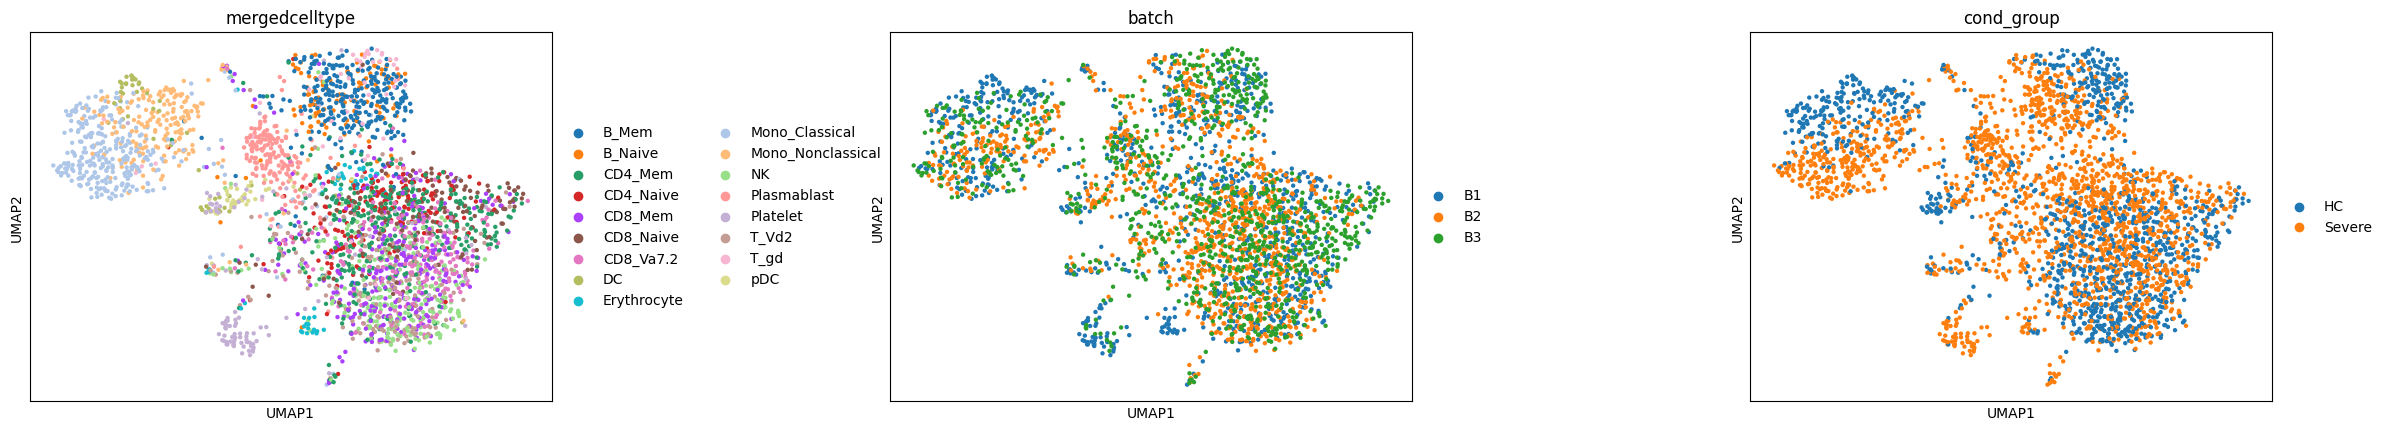

In [6]:
sc.pp.neighbors(rna, use_rep="X_m3")
sc.tl.umap(rna)
sc.pl.umap(rna, color=["mergedcelltype", "batch", "cond_group"], wspace=0.5, show=False)
plt.savefig("umap_m3.png", dpi=130, bbox_inches="tight")
plt.show()

In [7]:
rna.write_h5ad("rna_m3.h5ad")          # your AnnData, with the embedding in obsm["X_m3"]

From here everything works as in the other tutorials. Add `celltype_key="..."`
and `donor_key="..."` to `m3.M3` for
[patient prediction](https://pyanglab.github.io/M3/notebooks/py_02_patient_prediction/) and
[attribution](https://pyanglab.github.io/M3/notebooks/py_03_attribution/).

## 6. Other file layouts

Only step 2 changes. Steps 4 and 5 stay as they are. The cells below make
their example files from the objects above, so with your own data take only the
part that matches your layout.

### One set of files per batch

Combine each modality's files with anndata first, then read the combined
objects with `m3.from_anndata`, which works like `read_h5ad` on AnnData already
in memory. `label="batch"` adds the batch column, which files like these lack,
and `index_unique="-"` appends the batch to the cell names, so barcodes that
repeat across batches stay distinct and match between the modalities. Features
must have the same names in every batch.

In [8]:
adt = ad.read_h5ad("adt.h5ad")[rna.obs_names].copy()   # example files, one pair per batch
for b in ["B1", "B2", "B3"]:
    keep = rna.obs_names[rna.obs["batch"] == b]
    part = rna[keep, :].copy()
    del part.obs["batch"]                          # the batch is only in the file name
    part.write_h5ad(f"{b}_rna.h5ad")
    adt[keep, :].write_h5ad(f"{b}_adt.h5ad")

In [9]:
batches = ["B1", "B2", "B3"]
rna_all = ad.concat([ad.read_h5ad(f"{b}_rna.h5ad") for b in batches],
                    label="batch", keys=batches, index_unique="-")
adt_all = ad.concat([ad.read_h5ad(f"{b}_adt.h5ad") for b in batches],
                    label="batch", keys=batches, index_unique="-")
data = m3.from_anndata({"rna": rna_all, "adt": adt_all})
print(data)

cells per batch ('batch') and modality:
     rna   adt
B1  1000  1000
B2  1000  1000
B3  1000  1000
Dataset(n_cells=3000, batches=['B1', 'B2', 'B3'], modalities=[rna:1000, adt:192])


If the `obs` of every file already has a batch column, leave out `label=` and
`keys=`. For batches that do not all have the same modalities, see
[Mosaic integration](https://pyanglab.github.io/M3/notebooks/py_06_mosaic_integration/).

### One `.h5ad` holding every modality

If all features sit in one AnnData and `var["feature_types"]` says which is
which (`Gene Expression`, `Antibody Capture`, `Peaks`, as written by Cell
Ranger), `m3.from_anndata` replaces step 2. It splits the modalities and
adds the `obs_names` column itself. The column must be called `feature_types` and
hold exactly these values; features with any other value are left out, so check
the modalities in `print(data)`. Name the batch column with `batch_key=` in
step 4 if it is not called `batch`, and use this AnnData in place of `rna` in
step 5.

In [10]:
protein = adt.copy()                                # example file with both modalities
protein.var_names = protein.var_names + "_protein"
both = ad.concat([rna, protein], axis=1, merge="first")
both.var["feature_types"] = ["Gene Expression"] * rna.n_vars + ["Antibody Capture"] * adt.n_vars
both.write_h5ad("multimodal.h5ad")

In [11]:
both = ad.read_h5ad("multimodal.h5ad")
data = m3.from_anndata(both)
print(data)

Dataset(n_cells=3000, batches=['B1', 'B2', 'B3'], modalities=[rna:1000, adt:192])


If some batches in that file lack a modality, the file holds zeros for them,
not measurements. Split the AnnData into one object per modality and leave
those batches out of the modality they lack:

In [12]:
is_rna = (both.var["feature_types"] == "Gene Expression").to_numpy()
rna_part = both[:, is_rna]
adt_part = both[both.obs["batch"] != "B3", ~is_rna]           # as if B3 had no ADT
data = m3.from_anndata({"rna": rna_part, "adt": adt_part})
print(data)

cells per batch ('batch') and modality:
     rna   adt
B1  1000  1000
B2  1000  1000
B3  1000     0
Dataset(n_cells=3000, batches=['B1', 'B2', 'B3'], modalities=[rna:1000, adt:192])


### Seurat or SingleCellExperiment

Use the R package: see
[Use your own data (R)](https://pyanglab.github.io/M3/notebooks/r_05_own_data/).

## 7. Check before a long run

- **Modality names.** A modality with any other name than `rna`, `adt`, `atac`
  is left out of the model without an error.
- **Empty cells.** A cell whose counts in one modality are all zero is treated
  as not measured in that modality during training, whatever `data.present` says.
- **Number of features.** Counts are converted to dense matrices for training,
  so keep the variable features rather than every gene or peak. The cell below
  keeps the top genes and leaves the counts raw.
- **Batch sizes.** With the default `balance_batches=True`, training uses the
  same number of cells from every batch, set by the smallest one. The embedding
  is still returned for all cells.

In [13]:
tmp = rna.copy()
sc.pp.normalize_total(tmp, target_sum=1e4)
sc.pp.log1p(tmp)
sc.pp.highly_variable_genes(tmp, n_top_genes=500, batch_key="batch")
rna_hvg = rna[:, tmp.var["highly_variable"]].copy()       # still raw counts
print(rna_hvg.shape)

(3000, 500)
